<a href="https://colab.research.google.com/github/labrahmidoha2627encg-stack/25007644_LABRAHMI_Doha_FIN3/blob/main/projet_F3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# F3 — Prévision de l'inflation américaine à 12 mois

**Étudiante :** LABRAHMI Doha

**Apogée :** 25007644

**Filière :** S7 FIN3  

**Projet de référence :** Projet F3 – Prévisions Inflation  

**Date de réalisation :** 17/11/2026

## 1. Sujet et problématique

**Intérêt.** Anticiper l'inflation aide les banques centrales, les investisseurs et les entreprises à apprécier l'évolution du pouvoir d'achat, des taux réels et des coûts de financement.  
**Problématique.** Dans quelle mesure l'inflation passée, le taux de chômage et le taux directeur permettent-ils de prévoir l'inflation américaine à un horizon de 12 mois ?  
**Objectif mesurable.** Minimiser le RMSE (en points de pourcentage) sur une période de test chronologique postérieure à l'entraînement. Le modèle Ridge est considéré comme intéressant s'il réduit le RMSE d'au moins 5 % par rapport à la référence de persistance ; ce seuil est fixé avant l'examen des résultats de test.  
**Nature du problème.** Régression supervisée sur séries mensuelles : la cible est numérique et continue.  
**Algorithme principal :** Ridge Regression, algorithme n° 2 de l'annexe A. Gradient Boosting (n° 7) sera utilisé uniquement comme comparaison facultative.

## Configuration et reproductibilité

Les fichiers bruts sont lus depuis `data/raw/` avec des chemins relatifs. Les calculs utilisent une graine fixe. Les transformations apprenant des paramètres sont placées dans un pipeline et ajustées uniquement sur les données d'entraînement de chaque pli.

In [ ]:
# ============================================================
# 0. CONFIGURATION GÉNÉRALE ET REPRODUCTIBILITÉ
# ============================================================

# Importer les outils standards pour gérer les chemins, la version de Python
# et les éventuels avertissements pendant l'exécution.
from pathlib import Path
import sys, warnings

# Importer les bibliothèques de calcul et de manipulation des données.
import numpy as np
import pandas as pd

# Importer les bibliothèques de visualisation.
import matplotlib.pyplot as plt
import seaborn as sns

# Importer scikit-learn et les outils nécessaires à la préparation,
# à la validation chronologique, à la modélisation et à l'évaluation.
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, cross_val_score
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance
from IPython.display import display

# Fixer une graine aléatoire pour rendre les résultats reproductibles.
GRAINE = 42
np.random.seed(GRAINE)

# Définir le dossier racine du projet.
# Le notebook doit être lancé depuis la racine du projet pour que ces chemins
# relatifs pointent vers les bons dossiers.
ROOT = Path.cwd()

# Définir le chemin des fichiers CSV bruts et celui des graphiques exportés.
DATA_DIR = ROOT / "data" / "raw"
FIG_DIR = ROOT / "figures"

# Créer le dossier figures s'il n'existe pas encore.
FIG_DIR.mkdir(exist_ok=True, parents=True)

# Définir un style homogène pour tous les graphiques.
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

# Afficher les versions utilisées afin de documenter l'environnement.
print("Dossier racine :", ROOT.resolve())
print("Dossier des données :", DATA_DIR.resolve())
print("Python :", sys.version.split()[0])
print("pandas :", pd.__version__, "| NumPy :", np.__version__,
      "| scikit-learn :", sklearn.__version__)

Dossier racine : /content
Dossier des données : /content/data/raw
Python : 3.13.18
pandas : 2.2.3 | NumPy : 2.4.6 | scikit-learn : 1.6.1


## 2. Jeu de données

Les trois séries proviennent de **FRED (Federal Reserve Bank of St. Louis)** :
- CPIAUCSL : https://fred.stlouisfed.org/series/CPIAUCSL
- UNRATE : https://fred.stlouisfed.org/series/UNRATE
- FEDFUNDS : https://fred.stlouisfed.org/series/FEDFUNDS



| Variable | Description | Type / unité | Rôle |
|---|---|---|---|
| observation_date | Mois de référence | Date | Index temporel |
| CPIAUCSL | Indice des prix à la consommation, désaisonnalisé | Numérique, indice | Construction de la cible |
| UNRATE | Taux de chômage américain | Numérique, % | Explicative |
| FEDFUNDS | Taux effectif des fonds fédéraux | Numérique, % | Explicative |
| INFLATION_YOY | Variation du CPI sur 12 mois | Numérique, % | Inflation courante |
| TARGET_INFLATION_12M | Inflation YoY observée 12 mois après la date de départ | Numérique, % | Cible |
| *_LAG_k | Valeur d'une variable k mois auparavant | Numérique, unité de la variable | Explicative |

**Limites des sources.** Les séries macroéconomiques historiques peuvent être révisées. Les fichiers ne documentent pas les dates de publication en temps réel : certaines valeurs du mois courant n'étaient pas nécessairement disponibles à la date de prévision. L'expérience est donc pédagogique et ne constitue pas un véritable exercice « temps réel » sans biais de disponibilité. Les dates manquantes et la période de couverture différente des trois séries sont également prises en compte.

In [ ]:
# ============================================================
# 1. IMPORTATION DES BIBLIOTHEQUES
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

# ============================================================
# 2. DEFINITION DE LA FONCTION DE LECTURE
# ============================================================

def read_fred(path, value_col):
    # Lire le fichier CSV ; les points et cellules vides sont considérés comme des valeurs manquantes.
    d = pd.read_csv(path, na_values=[".", ""])

    # Vérifier que le fichier contient les deux colonnes attendues.
    colonnes_requises = {"observation_date", value_col}
    if not colonnes_requises.issubset(d.columns):
        raise ValueError(
            f"Le fichier {path.name} doit contenir les colonnes "
            f"{sorted(colonnes_requises)}. Colonnes trouvées : {list(d.columns)}"
        )

    # Convertir la date au format datetime pour permettre l'alignement temporel.
    d["observation_date"] = pd.to_datetime(d["observation_date"])

    # Ne conserver que la date et la variable étudiée, en supprimant les doublons de dates.
    d = d[["observation_date", value_col]].drop_duplicates("observation_date")

    # Utiliser la date comme index et retourner la série numérique.
    return d.set_index("observation_date")[value_col]

# ============================================================
# 3. CONNEXION A GOOGLE DRIVE
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

# ============================================================
# 4. DEFINITION DU CHEMIN D'ACCES AUX DONNEES
# ============================================================

# Chemin du dossier contenant les trois fichiers CSV
DATA_DIR = Path('/content/drive/MyDrive')

# Vérifier que le dossier existe
if not DATA_DIR.exists():
    raise FileNotFoundError("Le dossier est introuvable dans Google Drive.")

# ============================================================
# 5. CHARGEMENT DES TROIS DATASETS
# ============================================================

# Charger l'indice des prix à la consommation
cpi = read_fred(DATA_DIR / "CPIAUCSL.csv", "CPIAUCSL")

# Charger le taux de chômage
unrate = read_fred(DATA_DIR / "UNRATE.csv", "UNRATE")

# Charger le taux directeur de la FED
fedfunds = read_fred(DATA_DIR / "FEDFUNDS.csv", "FEDFUNDS")

# ============================================================
# 6. VERIFICATION DU CHARGEMENT
# ============================================================

print("Chargement des trois datasets effectué avec succès.")

print("\nCPIAUCSL :")
print(cpi.head())

print("\nUNRATE :")
print(unrate.head())

print("\nHARGE :")
print(fedfunds.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Chargement des trois datasets effectué avec succès.

CPIAUCSL :
observation_date
1947-01-01    21.48
1947-02-01    21.62
1947-03-01    22.00
1947-04-01    22.00
1947-05-01    21.95
Name: CPIAUCSL, dtype: float64

UNRATE :
observation_date
1948-01-01    3.4
1948-02-01    3.8
1948-03-01    4.0
1948-04-01    3.9
1948-05-01    3.5
Name: UNRATE, dtype: float64

HARGE :
observation_date
1954-07-01    0.80
1954-08-01    1.22
1954-09-01    1.07
1954-10-01    0.85
1954-11-01    0.83
Name: FEDFUNDS, dtype: float64


In [ ]:
# ============================================================
# 2. CHARGEMENT, CONTRÔLE ET FUSION DES SÉRIES FRED
# ============================================================

# Définir une fonction réutilisable pour lire chaque fichier FRED.
def read_fred(path, value_col):
    # Lire le fichier CSV ; les points et cellules vides sont considérés
    # comme des valeurs manquantes.
    d = pd.read_csv(path, na_values=[".", ""])

    # Vérifier que le fichier contient les deux colonnes attendues.
    colonnes_requises = {"observation_date", value_col}
    if not colonnes_requises.issubset(d.columns):
        raise ValueError(
            f"Le fichier {path.name} doit contenir les colonnes "
            f"{sorted(colonnes_requises)}. Colonnes trouvées : {list(d.columns)}"
        )

    # Convertir la date au format datetime pour permettre l'alignement temporel.
    d["observation_date"] = pd.to_datetime(d["observation_date"])

    # Ne conserver que la date et la variable étudiée.
    # Supprimer les éventuelles dates dupliquées.
    d = d[["observation_date", value_col]].drop_duplicates("observation_date")

    # Utiliser la date comme index et retourner la série numérique.
    return d.set_index("observation_date")[value_col]


# Charger chaque dataset à partir de Google Drive.
cpi = read_fred(DATA_DIR / "CPIAUCSL.csv", "CPIAUCSL")
unrate = read_fred(DATA_DIR / "UNRATE.csv", "UNRATE")
fedfunds = read_fred(DATA_DIR / "FEDFUNDS.csv", "FEDFUNDS")

# Fusionner les trois séries en fonction de leur date d'observation.
d = pd.concat([cpi, unrate, fedfunds], axis=1).sort_index()

# Construire un calendrier mensuel régulier (début de mois).
df = d.asfreq("MS")

# Calculer l'inflation annuelle en pourcentage à partir du CPI :
# (CPI_t / CPI_t-12 - 1) * 100.
df["INFLATION_YOY"] = df["CPIAUCSL"].pct_change(12, fill_method=None) * 100

# Afficher les dimensions, la période, les types et les valeurs manquantes
print("Dimensions du tableau mensuel fusionné :", df.shape)
print("Période :", df.index.min().date(), "à", df.index.max().date())

# Afficher les statistiques descriptives de df
display(df.describe().T.round(3))

Dimensions du tableau mensuel fusionné : (958, 4)
Période : 1947-01-01 à 2026-10-01


,count,mean,std,min,25%,50%,75%,max
CPIAUCSL,956.0,125.806,91.039,21.480,32.895,110.300,202.825,336.298
UNRATE,944.0,5.653,1.704,2.500,4.300,5.450,6.700,14.800
FEDFUNDS,868.0,4.593,3.524,0.050,1.945,4.245,6.105,19.100
INFLATION_YOY,944.0,3.519,2.859,-2.988,1.671,2.868,4.415,14.592


**Adéquation.** Le CPI permet de calculer une inflation annuelle comparable dans le temps. Le chômage et le taux directeur représentent deux indicateurs macroéconomiques pertinents pour étudier les dynamiques de demande et de politique monétaire. Leur disponibilité mensuelle permet de les aligner. Ces variables ne suffisent toutefois pas à représenter tous les déterminants de l'inflation (énergie, offre, taux de change, anticipations, etc.).

## 3. Exploration des données

Les statistiques descriptives sont calculées sur les observations disponibles. Les valeurs extrêmes ne sont pas supprimées automatiquement : elles peuvent correspondre à des épisodes économiques réels.

In [ ]:
# Calculer les statistiques descriptives (moyenne, écart-type, quartiles, etc.)
# pour comprendre l'échelle et la dispersion des variables.
display(df.describe().T.round(3))

# Vérifier l'existence de dates dupliquées dans l'index temporel.
print("Doublons de dates :", df.index.duplicated().sum())

# Mesurer la proportion de valeurs manquantes pour chaque variable.
# Cette vérification aide à décider du traitement avant la modélisation.
print("Part de valeurs manquantes (%) :")
display((df.isna().mean() * 100).round(2))

,count,mean,std,min,25%,50%,75%,max
CPIAUCSL,956.0,125.806,91.039,21.480,32.895,110.300,202.825,336.298
UNRATE,944.0,5.653,1.704,2.500,4.300,5.450,6.700,14.800
FEDFUNDS,868.0,4.593,3.524,0.050,1.945,4.245,6.105,19.100
INFLATION_YOY,944.0,3.519,2.859,-2.988,1.671,2.868,4.415,14.592


Doublons de dates : 0
Part de valeurs manquantes (%) :


,0
CPIAUCSL,0.21
UNRATE,1.46
FEDFUNDS,9.39
INFLATION_YOY,1.46


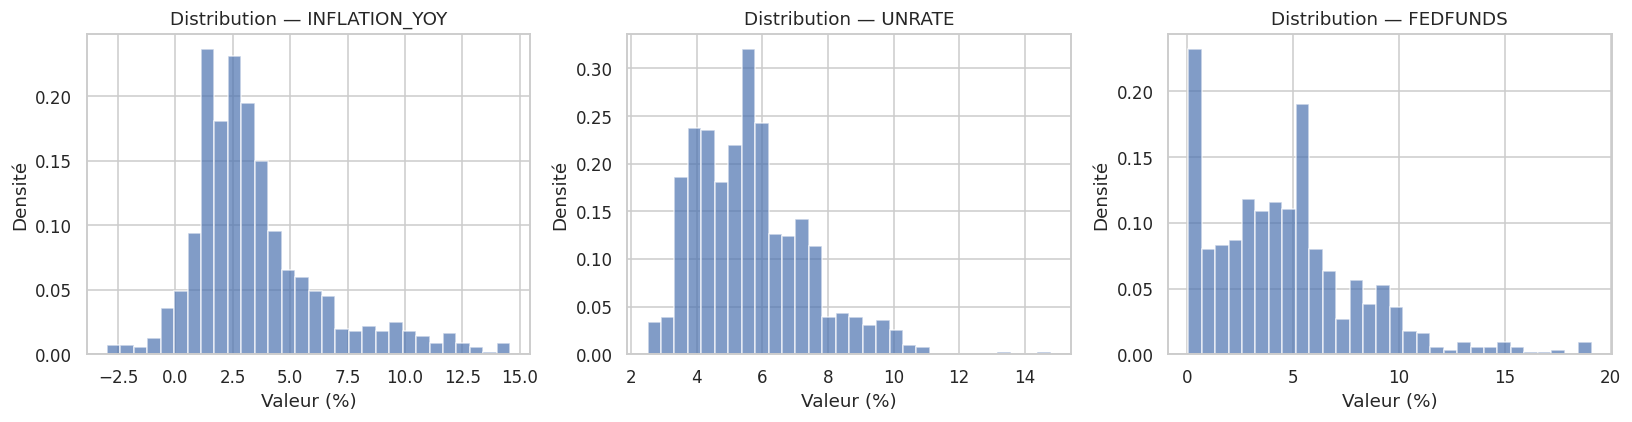

In [ ]:
# Sélectionner les trois variables macroéconomiques à examiner.
vars_plot = ["INFLATION_YOY", "UNRATE", "FEDFUNDS"]

# Tracer un histogramme par variable pour étudier leur distribution.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, vars_plot):
    # Ignorer uniquement les valeurs manquantes pour le graphique.
    ax.hist(df[col].dropna(), bins=30, density=True, alpha=0.7)
    ax.set_title(f"Distribution — {col}")
    ax.set_xlabel("Valeur (%)")
    ax.set_ylabel("Densité")

# Ajuster la mise en page, enregistrer le graphique et l'afficher.
plt.tight_layout()
fig.savefig(FIG_DIR / "01_distributions.png", bbox_inches="tight")
plt.show()

**Interprétation du graphique 1.** Les distributions permettent de repérer l'asymétrie et les épisodes de valeurs inhabituelles. L'inflation et les taux macroéconomiques ne suivent pas nécessairement une distribution normale ; les extrêmes doivent être interprétés dans leur contexte historique et non éliminés mécaniquement.

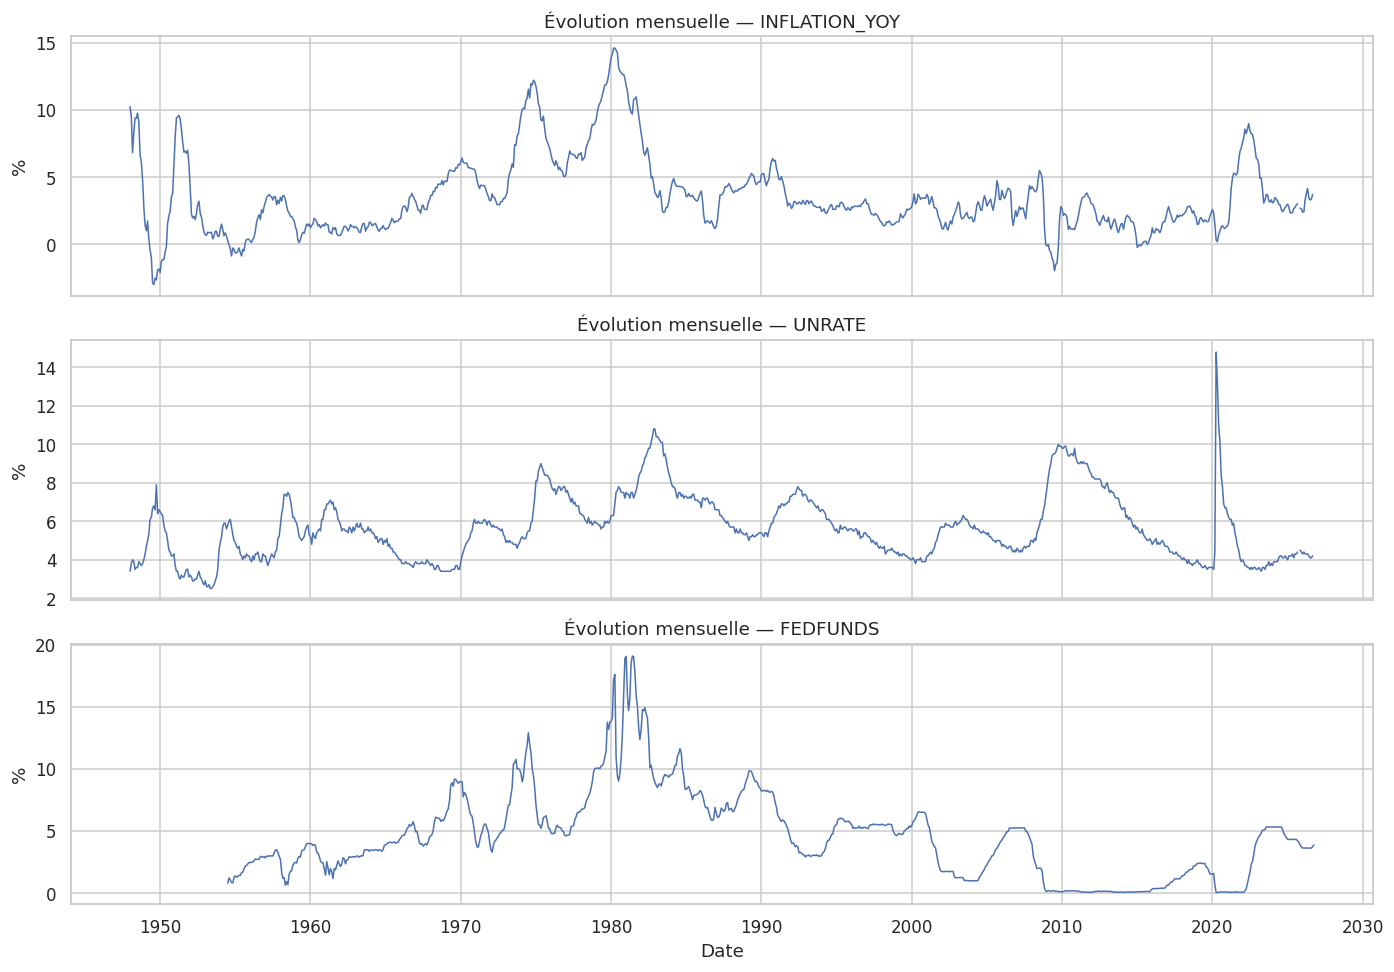

In [ ]:
# Tracer l'évolution historique de l'inflation, du chômage et du taux directeur.
fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)

for ax, col in zip(axes, vars_plot):
    # Utiliser les dates mensuelles en abscisse et la valeur en ordonnée.
    ax.plot(df.index, df[col], linewidth=1)
    ax.set_title(f"Évolution mensuelle — {col}")
    ax.set_ylabel("%")

# Ajouter le libellé de l'axe temporel, ajuster et sauvegarder la figure.
axes[-1].set_xlabel("Date")
plt.tight_layout()
fig.savefig(FIG_DIR / "02_evolutions.png", bbox_inches="tight")
plt.show()

**Interprétation du graphique 2.** Les séries présentent des cycles et des changements de régime, notamment autour des périodes de crise et des épisodes de resserrement/assouplissement monétaire. La relation entre les indicateurs peut varier dans le temps : une relation estimée sur toute la période peut ne pas rester stable.

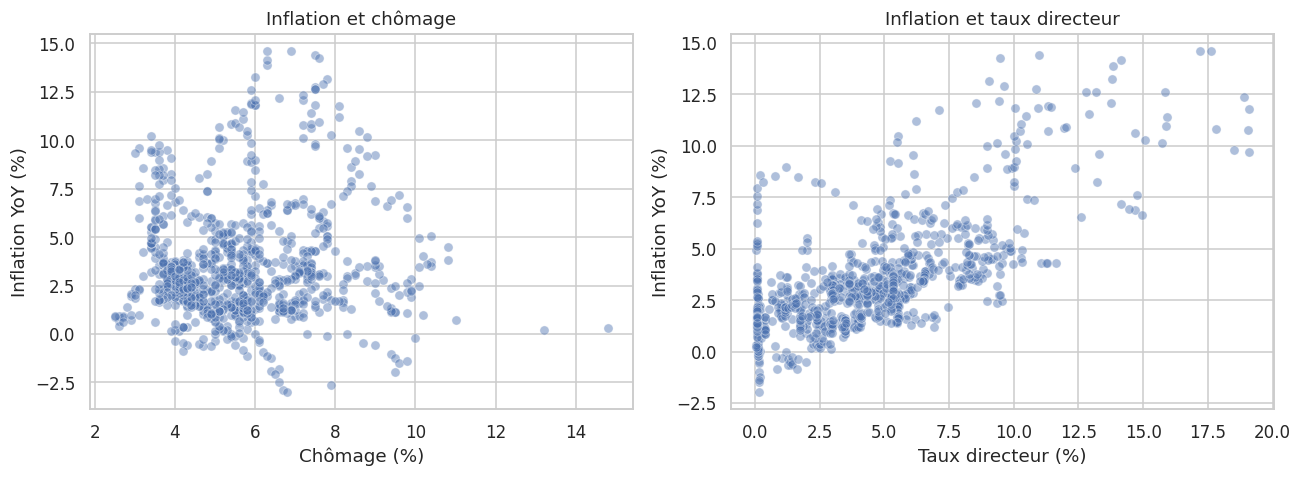

In [ ]:
# Étudier les relations descriptives entre l'inflation et les deux indicateurs.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Relation entre le taux de chômage et l'inflation annuelle.
sns.scatterplot(data=df, x="UNRATE", y="INFLATION_YOY",
                alpha=0.45, ax=axes[0])
axes[0].set(title="Inflation et chômage",
            xlabel="Chômage (%)", ylabel="Inflation YoY (%)")

# Relation entre le taux directeur et l'inflation annuelle.
sns.scatterplot(data=df, x="FEDFUNDS", y="INFLATION_YOY",
                alpha=0.45, ax=axes[1])
axes[1].set(title="Inflation et taux directeur",
            xlabel="Taux directeur (%)", ylabel="Inflation YoY (%)")

# Ajuster, enregistrer et afficher les deux nuages de points.
plt.tight_layout()
fig.savefig(FIG_DIR / "03_relations.png", bbox_inches="tight")
plt.show()

**Interprétation du graphique 3.** Les nuages de points montrent les associations contemporaines, potentiellement non linéaires et influencées par les régimes économiques. Ils ne prouvent aucune causalité et ne suffisent pas à démontrer un pouvoir prédictif ; c'est pourquoi la modélisation utilise des retards et une validation chronologique.

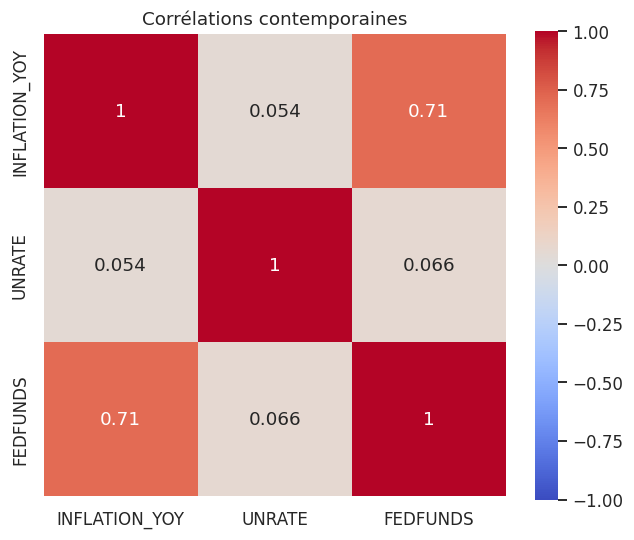

,INFLATION_YOY,UNRATE,FEDFUNDS
INFLATION_YOY,1.000,0.054,0.708
UNRATE,0.054,1.000,0.066
FEDFUNDS,0.708,0.066,1.000


In [ ]:
# Calculer les corrélations linéaires contemporaines entre les variables.
corr = df[vars_plot].corr()

# Représenter la matrice sous forme de carte thermique annotée.
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1,
            square=True, ax=ax)
ax.set_title("Corrélations contemporaines")

# Enregistrer la figure puis afficher les coefficients numériques.
plt.tight_layout()
fig.savefig(FIG_DIR / "04_correlations.png", bbox_inches="tight")
plt.show()
display(corr.round(3))

## 4. Préparation des données et prévention des fuites

La cible est l'inflation annuelle observée 12 mois après la date d'origine : `shift(-12)`. Les variables explicatives comprennent les valeurs contemporaines (à la date d'origine) et les retards de 1, 3, 6 et 12 mois. Le calendrier mensuel complet est conservé avant les décalages ; les lignes incomplètes sont retirées ensuite. Les dates de test sont postérieures aux dates d'entraînement. Un intervalle de 12 mois (`gap=12`) limite le chevauchement des horizons. L'imputation et la standardisation sont incluses dans un pipeline, donc ajustées seulement sur chaque échantillon d'entraînement.

In [ ]:
# Copier les données initiales afin de construire le jeu de modélisation.
df_model = df.copy()

# Définir la cible : inflation annuelle observée 12 mois après la date d'origine.
# shift(-12) place la valeur future sur la ligne de la date de prévision.
df_model["TARGET_INFLATION_12M"] = df_model["INFLATION_YOY"].shift(-12)

# Définir les variables macroéconomiques explicatives.
base_vars = ["INFLATION_YOY", "UNRATE", "FEDFUNDS"]

# Créer des variables retardées de 1, 3, 6 et 12 mois.
# Chaque retard utilise uniquement une information passée ou disponible à t.
for v in base_vars:
    for lag in [1, 3, 6, 12]:
        df_model[f"{v}_LAG_{lag}"] = df_model[v].shift(lag)

# Rassembler les noms de toutes les variables explicatives.
features = base_vars + [
    f"{v}_LAG_{lag}" for v in base_vars for lag in [1, 3, 6, 12]
]
target = "TARGET_INFLATION_12M"

# Supprimer les lignes incomplètes uniquement après création des retards
# et de la cible, car elles ne peuvent pas être utilisées pour l'apprentissage.
data = df_model.dropna(subset=features + [target]).copy()
X, y = data[features], data[target]

# Vérifier le nombre d'observations et l'alignement des variables.
print("Observations modélisables :", len(data),
      "| Variables explicatives :", len(features))
display(data[["TARGET_INFLATION_12M"] + features].head())

Observations modélisables : 842 | Variables explicatives : 15


,TARGET_INFLATION_12M,INFLATION_YOY,UNRATE,FEDFUNDS,INFLATION_YOY_LAG_1,INFLATION_YOY_LAG_3,INFLATION_YOY_LAG_6,INFLATION_YOY_LAG_12,UNRATE_LAG_1,UNRATE_LAG_3,UNRATE_LAG_6,UNRATE_LAG_12,FEDFUNDS_LAG_1,FEDFUNDS_LAG_3,FEDFUNDS_LAG_6,FEDFUNDS_LAG_12
observation_date,,,,,,,,,,,,,,,,
1955-07-01,1.980568,-0.372301,4.0,1.68,-0.853749,-0.260611,-0.631032,0.261292,4.2,4.7,4.9,5.8,1.64,1.43,1.39,0.80
1955-08-01,2.208084,-0.484171,4.2,1.96,-0.372301,-0.594133,-0.629863,0.000000,4.0,4.3,4.7,6.0,1.68,1.43,1.29,1.22
1955-09-01,1.862197,0.149198,4.1,2.18,-0.484171,-0.853749,-0.519866,-0.297508,4.2,4.2,4.6,6.1,1.96,1.64,1.35,1.07
1955-10-01,2.572707,0.374251,4.3,2.24,0.149198,-0.372301,-0.260611,-0.853432,4.1,4.0,4.7,5.7,2.18,1.68,1.43,0.85
1955-11-01,2.343750,0.373413,4.2,2.35,0.374251,-0.484171,-0.594133,-0.260708,4.3,4.2,4.3,5.3,2.24,1.96,1.43,0.83


In [ ]:
# Définir un découpage chronologique : les observations les plus anciennes
# servent à l'entraînement et les plus récentes constituent le test.
split = int(len(data) * 0.80)

# Réserver un embargo de 12 mois entre entraînement et test.
# Il limite le chevauchement des horizons de prévision à 12 mois.
train_end = split - 12

# Vérifier que l'échantillon restant est suffisamment grand.
if train_end <= 60 or split >= len(data):
    raise ValueError("Échantillon trop petit pour le découpage choisi.")

# Séparer les variables explicatives et la cible sans mélanger les dates.
X_train, y_train = X.iloc[:train_end], y.iloc[:train_end]
X_test, y_test = X.iloc[split:], y.iloc[split:]

# Conserver les dates d'origine et les dates auxquelles les cibles sont observées.
dates_train = data.index[:train_end]
dates_test_origin = data.index[split:]
dates_test_target = dates_test_origin + pd.DateOffset(months=12)

# Afficher les périodes pour documenter le protocole expérimental.
print("Train :", dates_train.min().date(), "à",
      dates_train.max().date(), "n =", len(X_train))
print("Test (origines) :", dates_test_origin.min().date(), "à",
      dates_test_origin.max().date(), "n =", len(X_test))
print("Période cible du test :", dates_test_target.min().date(),
      "à", dates_test_target.max().date())

Train : 1955-07-01 à 2010-07-01 n = 661
Test (origines) : 2011-08-01 à 2025-09-01 n = 169
Période cible du test : 2012-08-01 à 2026-09-01


## 5. Algorithme principal : Ridge Regression (algorithme n° 2)

La régression Ridge minimise la somme des carrés des résidus à laquelle s'ajoute une pénalité quadratique sur les coefficients. Sa fonction objectif est :

\[
\hat{\beta}=\arg\min_{\beta}\left[\sum_{i=1}^{n}(y_i-\beta_0-x_i^T\beta)^2+\alpha\sum_{j=1}^{p}\beta_j^2\right].
\]

`n` désigne le nombre d'observations d'entraînement, `p` le nombre de variables, `y_i` la cible, `x_i` le vecteur des variables de l'observation `i`, `β0` l'interception, `βj` les coefficients appris et `α` l'hyperparamètre de régularisation. Lorsque `α` augmente, les coefficients sont davantage pénalisés, ce qui réduit leur amplitude et peut limiter le surapprentissage. Les coefficients sont les paramètres appris ; `α` est choisi par validation. La standardisation est utile car les variables ont des échelles différentes.

Ridge est adapté à un petit jeu macroéconomique, à des variables corrélées et à un besoin d'interprétation relativement simple. Une régression linéaire ordinaire ne pénalise pas les coefficients et peut être instable en présence de multicolinéarité. Le Gradient Boosting peut capturer des non-linéarités, mais est moins directement interprétable et peut surapprendre sur un échantillon limité.

## 6. Protocole expérimental

**Référence naïve obligatoire :** persistance, c'est-à-dire prévoir à 12 mois l'inflation actuellement observée. La métrique principale est le RMSE, exprimé en points de pourcentage ; il pénalise davantage les grandes erreurs. Le MAE (même unité) est secondaire et mesure l'erreur absolue moyenne. Le coefficient R² est également présenté, mais peut être négatif sur un test difficile. Le réglage de Ridge porte uniquement sur `alpha` avec une validation `TimeSeriesSplit` à cinq plis et un écart de 12 mois. Le test final n'intervient pas dans le choix des hyperparamètres.

In [ ]:
# Définir une référence naïve de persistance :
# la prévision à 12 mois est égale à l'inflation connue à la date d'origine.
from sklearn.base import BaseEstimator, RegressorMixin

class PersistenceBaseline(BaseEstimator, RegressorMixin):
    # La référence n'apprend aucun paramètre à partir de y.
    def fit(self, X, y):
        return self

    # Retourner la valeur contemporaine de l'inflation comme prévision.
    def predict(self, X):
        return np.asarray(X["INFLATION_YOY"])


# Instancier la référence naïve.
baseline = PersistenceBaseline()

# Construire un pipeline Ridge : imputation, standardisation, puis régression.
# Les transformations sont apprises uniquement sur les données de chaque pli.
ridge_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", Ridge())
])

# Construire un modèle Gradient Boosting de comparaison.
# L'imputation est intégrée au pipeline ; les paramètres du modèle sont fixés.
gb_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", GradientBoostingRegressor(
        random_state=GRAINE, n_estimators=100,
        learning_rate=0.03, max_depth=2, loss="squared_error"
    ))
])

# Créer une validation croisée adaptée aux séries temporelles.
# Les plis respectent l'ordre chronologique et incluent un gap de 12 mois.
tscv = TimeSeriesSplit(n_splits=5, gap=12)

# Tester cinq valeurs de alpha pour choisir le niveau de régularisation Ridge.
# Le réglage est effectué uniquement sur l'échantillon d'entraînement.
grid = GridSearchCV(
    ridge_pipe,
    param_grid={"model__alpha": [0.01, 0.1, 1, 10, 100]},
    scoring="neg_root_mean_squared_error",
    cv=tscv, n_jobs=-1, refit=True
)
grid.fit(X_train, y_train)

# Récupérer le meilleur pipeline et présenter les résultats de validation.
ridge_best = grid.best_estimator_
print("Meilleur alpha :", grid.best_params_["model__alpha"])
print("RMSE moyen validation :", -grid.best_score_)
print("Nombre de configurations testées :", len(grid.cv_results_["params"]))

Meilleur alpha : 100
RMSE moyen validation : 2.7000710590694315
Nombre de configurations testées : 5


In [ ]:
# Comparer les trois approches sur les mêmes plis chronologiques.
# Le score négatif de scikit-learn est converti en RMSE positif.
cv_rows = []
for name, estimator in [
    ("Persistance", baseline),
    ("Ridge réglé", ridge_best),
    ("Gradient Boosting", gb_pipe)
]:
    # Calculer le RMSE sur chacun des plis de validation.
    sc = cross_val_score(
        estimator, X_train, y_train, cv=tscv,
        scoring="neg_root_mean_squared_error", n_jobs=-1
    )

    # Conserver la moyenne et l'écart-type pour mesurer la stabilité.
    cv_rows.append({
        "Modèle": name,
        "RMSE validation moyen": -sc.mean(),
        "Écart-type validation": sc.std()
    })

# Présenter les scores moyens et leur variabilité.
cv_table = pd.DataFrame(cv_rows)
display(cv_table.round(3))

,Modèle,RMSE validation moyen,Écart-type validation
0,Persistance,1.996,0.754
1,Ridge réglé,2.700,1.373
2,Gradient Boosting,3.342,1.253


## 7. Résultats et évaluation finale

Le modèle Ridge est réglé uniquement sur l'entraînement. Les modèles sont ensuite réajustés sur l'entraînement complet et évalués sur le test chronologique, une seule fois. Le tableau inclut la référence naïve et le modèle de comparaison.

In [ ]:
# Définir une fonction pour calculer les trois métriques de régression.
def metrics_row(name, actual, pred):
    return {
        "Modèle": name,
        "RMSE": float(np.sqrt(mean_squared_error(actual, pred))),
        "MAE": float(mean_absolute_error(actual, pred)),
        "R2": float(r2_score(actual, pred))
    }

# Entraîner chaque approche sur l'ensemble d'entraînement puis prédire le test.
# Le jeu de test est réservé à cette évaluation finale.
predictions = {}
for name, estimator in [
    ("Persistance", baseline),
    ("Ridge réglé", ridge_best),
    ("Gradient Boosting", gb_pipe)
]:
    estimator.fit(X_train, y_train)
    predictions[name] = estimator.predict(X_test)

# Construire le tableau comparatif des performances sur le test.
test_table = pd.DataFrame([
    metrics_row(k, y_test, v) for k, v in predictions.items()
]).sort_values("RMSE")
display(test_table.round(3))

# Comparer le RMSE de Ridge à celui de la référence naïve.
base_rmse = float(test_table.loc[
    test_table["Modèle"] == "Persistance", "RMSE"
].iloc[0])
ridge_rmse = float(test_table.loc[
    test_table["Modèle"] == "Ridge réglé", "RMSE"
].iloc[0])
improvement = (base_rmse - ridge_rmse) / base_rmse * 100

# Vérifier si l'objectif fixé avant l'évaluation est atteint.
print(f"Réduction du RMSE Ridge vs persistance : {improvement:.2f} %")
print("Objectif de réduction d'au moins 5 % atteint :", improvement >= 5)

,Modèle,RMSE,MAE,R2
0,Persistance,2.084,1.470,-0.095
2,Gradient Boosting,2.367,1.649,-0.414
1,Ridge réglé,2.462,1.877,-0.530


Réduction du RMSE Ridge vs persistance : -18.17 %
Objectif de réduction d'au moins 5 % atteint : False


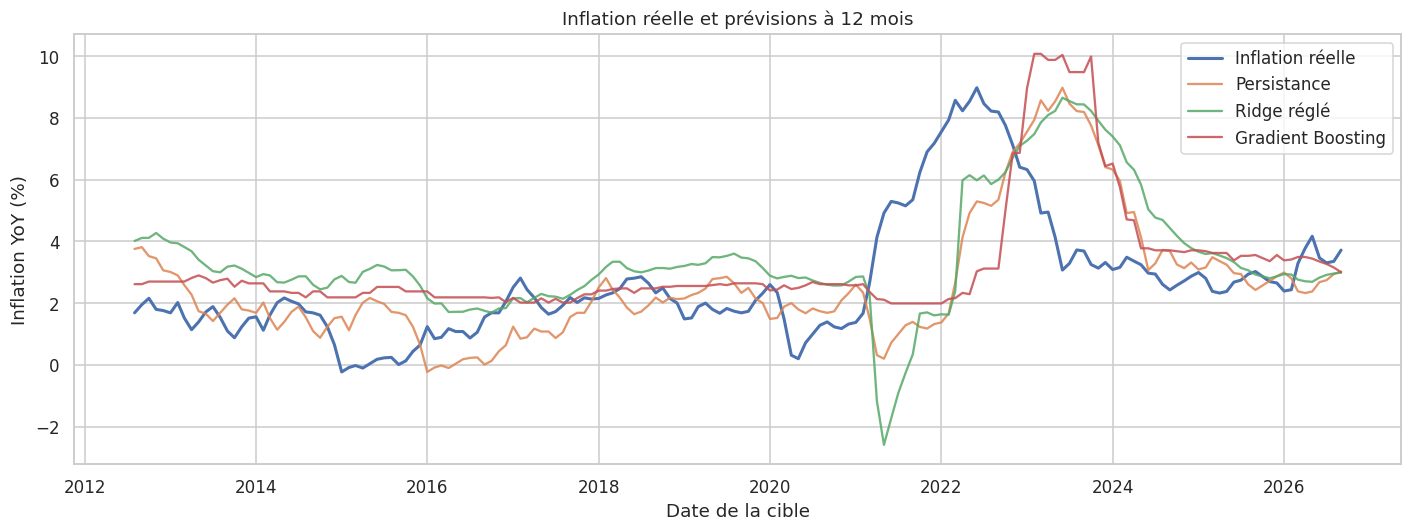

In [ ]:
# Comparer visuellement les prévisions de chaque approche à l'inflation réelle.
fig, ax = plt.subplots(figsize=(13, 5))

# Utiliser les dates de réalisation des cibles, et non les dates d'origine.
ax.plot(dates_test_target, y_test.to_numpy(),
        label="Inflation réelle", linewidth=2)

# Ajouter les prévisions de la référence et des deux modèles.
for name, pred in predictions.items():
    ax.plot(dates_test_target, pred, label=name, alpha=0.85)

# Ajouter le titre, les unités, la légende et sauvegarder la figure.
ax.set(
    title="Inflation réelle et prévisions à 12 mois",
    xlabel="Date de la cible",
    ylabel="Inflation YoY (%)"
)
ax.legend()
plt.tight_layout()
fig.savefig(FIG_DIR / "05_previsions_test.png", bbox_inches="tight")
plt.show()

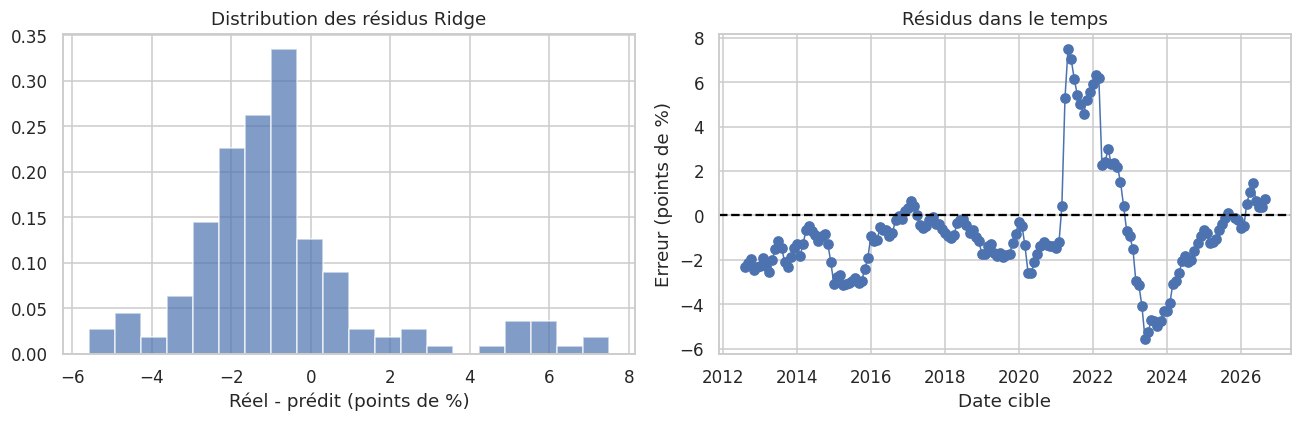

Biais moyen (résidu moyen) : -0.764
Erreur absolue maximale : 7.51


In [ ]:
# Calculer les résidus du modèle principal : valeur réelle moins prévision.
ridge_pred = predictions["Ridge réglé"]
residuals = y_test.to_numpy() - ridge_pred

# Tracer la distribution des erreurs et leur évolution dans le temps.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# L'histogramme permet d'observer la dispersion et l'asymétrie des résidus.
axes[0].hist(residuals, bins=20, density=True, alpha=0.7)
axes[0].set(
    title="Distribution des résidus Ridge",
    xlabel="Réel - prédit (points de %)"
)

# La courbe temporelle permet de repérer les périodes de biais du modèle.
axes[1].plot(dates_test_target, residuals, marker="o", linewidth=1)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set(
    title="Résidus dans le temps",
    xlabel="Date cible",
    ylabel="Erreur (points de %)"
)

# Enregistrer et afficher les diagnostics d'erreurs.
plt.tight_layout()
fig.savefig(FIG_DIR / "06_residus.png", bbox_inches="tight")
plt.show()

# Quantifier le biais moyen et la plus grande erreur absolue.
print("Biais moyen (résidu moyen) :", round(float(residuals.mean()), 3))
print("Erreur absolue maximale :", round(float(np.max(np.abs(residuals))), 3))

In [ ]:
# Construire un tableau détaillé des prévisions Ridge sur le jeu de test.
# Chaque ligne relie la date d'origine, la date cible, le réel et la prévision.
error_table = pd.DataFrame({
    "Date origine": dates_test_origin,
    "Date cible": dates_test_target,
    "Inflation réelle": y_test.to_numpy(),
    "Prévision Ridge": ridge_pred,
    "Résidu": residuals,
    "Erreur absolue": np.abs(residuals)
})

# Trier par erreur absolue décroissante pour identifier les cinq cas
# où le modèle s'est le plus éloigné de la valeur réellement observée.
error_table = error_table.sort_values("Erreur absolue", ascending=False)
display(error_table.head(5).round(3))

,Date origine,Date cible,Inflation réelle,Prévision Ridge,Résidu,Erreur absolue
105,2020-05-01,2021-05-01,4.918,-2.592,7.510,7.510
106,2020-06-01,2021-06-01,5.296,-1.733,7.029,7.029
114,2021-02-01,2022-02-01,7.937,1.625,6.312,6.312
115,2021-03-01,2022-03-01,8.572,2.392,6.180,6.180
107,2020-07-01,2021-07-01,5.245,-0.919,6.164,6.164


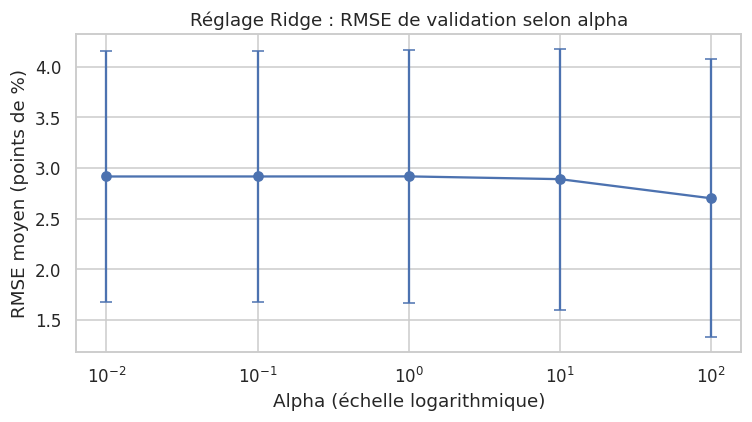

In [ ]:
# Extraire les résultats de GridSearchCV pour étudier l'effet de alpha.
cv_results = pd.DataFrame(grid.cv_results_)
alphas = cv_results["param_model__alpha"].astype(float)
mean_rmse = -cv_results["mean_test_score"]
std_rmse = cv_results["std_test_score"]

# Tracer le RMSE moyen de validation avec son écart-type.
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(alphas, mean_rmse, yerr=std_rmse, marker="o", capsize=4)

# Utiliser une échelle logarithmique car les valeurs de alpha sont espacées
# par facteurs de dix.
ax.set_xscale("log")
ax.set(
    title="Réglage Ridge : RMSE de validation selon alpha",
    xlabel="Alpha (échelle logarithmique)",
    ylabel="RMSE moyen (points de %)"
)

# Enregistrer et afficher la courbe de validation.
plt.tight_layout()
fig.savefig(FIG_DIR / "07_validation_alpha.png", bbox_inches="tight")
plt.show()

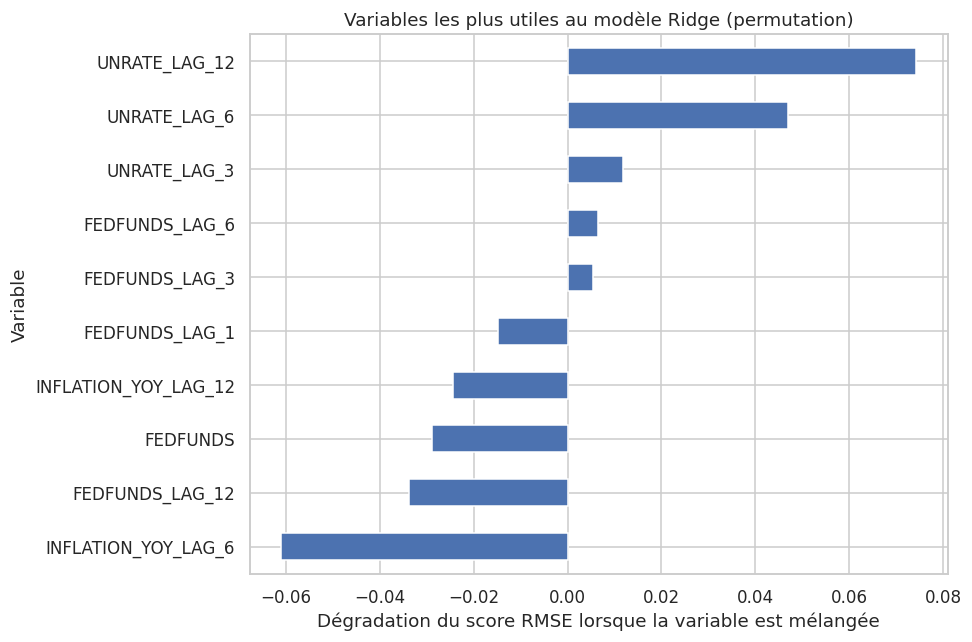

,0
UNRATE_LAG_12,0.0742
UNRATE_LAG_6,0.0470
UNRATE_LAG_3,0.0119
FEDFUNDS_LAG_6,0.0065
FEDFUNDS_LAG_3,0.0053
FEDFUNDS_LAG_1,-0.0148
INFLATION_YOY_LAG_12,-0.0243
FEDFUNDS,-0.0289
FEDFUNDS_LAG_12,-0.0337
INFLATION_YOY_LAG_6,-0.0609


In [ ]:
# Mesurer l'importance des variables par permutation.
# Cette méthode mélange une variable à la fois et mesure la dégradation du score.
# L'importance est interprétative et ne démontre pas une relation causale.
perm = permutation_importance(
    ridge_best, X_test, y_test, n_repeats=20,
    random_state=GRAINE, scoring="neg_root_mean_squared_error"
)

# Associer les importances aux noms des variables puis les trier.
perm_series = pd.Series(perm.importances_mean, index=features).sort_values()

# Représenter les dix variables dont l'importance estimée est la plus élevée.
fig, ax = plt.subplots(figsize=(9, 6))
perm_series.tail(10).plot(kind="barh", ax=ax)
ax.set(
    title="Variables les plus utiles au modèle Ridge (permutation)",
    xlabel="Dégradation du score RMSE lorsque la variable est mélangée",
    ylabel="Variable"
)

# Enregistrer et afficher le graphique ainsi que le classement complet.
plt.tight_layout()
fig.savefig(FIG_DIR / "08_importance_permutation.png", bbox_inches="tight")
plt.show()
display(perm_series.sort_values(ascending=False).head(10).round(4))

In [ ]:
# Sélectionner cinq observations du jeu de test, jamais utilisées
# pour ajuster les paramètres des modèles.
illustration = pd.DataFrame({
    "Date origine": dates_test_origin,
    "Date cible": dates_test_target,
    "Inflation réelle (%)": y_test.to_numpy(),
    "Prévision Ridge (%)": ridge_pred,
    "Erreur absolue (pt)": np.abs(y_test.to_numpy() - ridge_pred)
}).head(5)

# Afficher les entrées temporelles et les résultats pour illustrer un usage.
display(illustration.round(3))

,Date origine,Date cible,Inflation réelle (%),Prévision Ridge (%),Erreur absolue (pt)
0,2011-08-01,2012-08-01,1.686,4.014,2.328
1,2011-09-01,2012-09-01,1.950,4.112,2.162
2,2011-10-01,2012-10-01,2.156,4.115,1.959
3,2011-11-01,2012-11-01,1.796,4.273,2.477
4,2011-12-01,2012-12-01,1.760,4.089,2.329


## 8. Analyse critique et interprétation

L'analyse doit se concentrer sur les résultats effectivement produits par l'exécution du notebook. Une baisse du RMSE par rapport à la persistance indiquerait un gain prédictif sur la période test ; une absence de gain signifierait que les indicateurs retenus n'apportent pas suffisamment d'information supplémentaire dans ce protocole. Les coefficients Ridge décrivent des associations conditionnelles et non des effets causaux. Les erreurs les plus élevées doivent être rapprochées des changements de régime et des chocs économiques.

**Limites concrètes :** (1) révisions historiques des séries FRED ; (2) dates de publication non modélisées, donc risque de biais de disponibilité ; (3) nombre d'indicateurs limité ; (4) changement de régime possible entre entraînement et test ; (5) horizon de 12 mois et cibles qui se chevauchent, d'où l'embargo de 12 observations.  
**Améliorations possibles :** utiliser les versions ALFRED disponibles à chaque date, intégrer des indicateurs d'énergie et d'anticipations, comparer plusieurs fenêtres de test, et réaliser une évaluation à origine glissante.

## 9. Conclusion

L’étude montre que les trois séries macroéconomiques retenues ne permettent pas, dans le protocole testé, d’améliorer la prévision de l’inflation américaine à douze mois par rapport à la persistance. Le modèle Ridge obtient un RMSE de 2,462 contre 2,084 pour la référence, soit une dégradation de 18,17 %. L’objectif de réduction d’au moins 5 % du RMSE n’est donc pas atteint. La conclusion est limitée aux données disponibles, aux variables choisies et à la période de test ; elle ne permet pas d’établir de relation causale entre chômage, taux directeur et inflation.

In [ ]:
# Identifier le modèle qui obtient le RMSE le plus faible sur le test.
best_test = test_table.iloc[0]["Modèle"]

# Rappeler les scores utiles à la réponse à la problématique.
print(f"Modèle au RMSE test le plus faible : {best_test}")
print(f"RMSE persistance : {base_rmse:.3f} | RMSE Ridge : {ridge_rmse:.3f}")
print(f"Gain relatif Ridge vs persistance : {improvement:.2f} %")

# Conclure automatiquement selon le seuil de réussite fixé à l'avance.
if improvement >= 5:
    print("Conclusion : l'objectif prédéfini de réduction d'au moins 5 % "
          "du RMSE est atteint sur le test.")
else:
    print("Conclusion : l'objectif prédéfini de réduction d'au moins 5 % "
          "du RMSE n'est pas atteint sur le test.")

# Rappeler que la conclusion est conditionnelle à la période et aux données étudiées.
print("Cette conclusion reste limitée à la période test et aux données "
      "révisées disponibles.")

Modèle au RMSE test le plus faible : Persistance
RMSE persistance : 2.084 | RMSE Ridge : 2.462
Gain relatif Ridge vs persistance : -18.17 %
Conclusion : l'objectif prédéfini de réduction d'au moins 5 % du RMSE n'est pas atteint sur le test.
Cette conclusion reste limitée à la période test et aux données révisées disponibles.


## 10. Références et reproduction

- FRED, Consumer Price Index for All Urban Consumers: All Items in U.S. City Average, série CPIAUCSL : https://fred.stlouisfed.org/series/CPIAUCSL
- FRED, Unemployment Rate, série UNRATE : https://fred.stlouisfed.org/series/UNRATE
- FRED, Federal Funds Effective Rate, série FEDFUNDS : https://fred.stlouisfed.org/series/FEDFUNDS
- Documentation pandas : https://pandas.pydata.org/docs/
- Documentation scikit-learn, Ridge : https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html
- Documentation scikit-learn, TimeSeriesSplit : https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html

Pour reproduire : installer `requirements.txt`, conserver les trois CSV dans `data/raw/`, ouvrir `notebooks/projet_F3_partie_B.ipynb` depuis la racine du projet, puis exécuter toutes les cellules dans l'ordre.

## Déclaration des ressources et outils d'IA

| Outil ou ressource | Version/date | Usage précis | Parties concernées | Vérification |
|---|---|---|---|---|
| ChatGPT (GPT-6) | 17/11/2026 | Assistance à la structuration, rédaction, proposition et vérification du code | Notebook, rapport et présentation | Exécution du notebook, contrôle des calculs, vérification des sorties et adaptation par l'étudiante |
| Python, pandas, NumPy, matplotlib, seaborn, scikit-learn | Versions affichées à l'exécution | Analyse, visualisation, préparation, validation et modélisation | Toutes les sections quantitatives | Exécution reproductible du notebook |
